In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
!pip install category_encoders
import sklearn
import category_encoders as ce
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import GroupKFold

from sklearn.model_selection import RandomizedSearchCV

In [2]:
data = pd.read_csv("../preprocessed/diabetes_final.csv")

C:\Users\PC\AppData\Local\Temp\ipykernel_21736\4150673327.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("../preprocessed/diabetes_final.csv")


In [3]:
def data_overview(x):
 pd.set_option("display.max_columns",50)
 pd.set_option("display.max_rows", None)
 display(x.head(50))
 print(f"Number of rows:{x.shape[0]}\nNumber of columns:{x.shape[1]}")
 print(pd.DataFrame({
     "Data type:": x.dtypes,
     "Missing values:": x.isna().sum(), 
     "Percentage of na:": x.isna().mean()*100,
     "Value count:":  x.nunique()
 }))

In [4]:
data_overview(data)

,patient_nbr,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,miglitol,...,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,diag_1_reduced,diag_2_reduced,diag_3_reduced,has_circulatory,has_endocrine_metabolic,has_respiratory,has_digestive,has_genitourinary,has_skin,has_blood,has_mental,has_injury_poisoning,has_neoplasms,has_infectious,has_musculoskeletal,has_nervous,has_complications,readmitted
0,8222157,Caucasian,Female,[0-10),1,NaN,41,0,1,0,0,0,1,Not measured,No,No,No,No,No,No,No,No,No,No,No,...,No,No,No,Unknown,Unknown,Physician Referral,Pediatrics,250.8,NaN,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
1,55629189,Caucasian,Female,[10-20),3,NaN,59,0,18,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,276,250.0,255,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,86047875,AfricanAmerican,Female,[20-30),2,NaN,11,5,13,2,0,1,6,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,...,No,No,Yes,Emergency,Discharged to home,Emergency Room,Missing,648,250,V27,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,82442376,Caucasian,Male,[30-40),2,NaN,44,1,16,0,0,0,7,Not measured,No,No,No,No,No,No,No,No,No,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,008,250.4,403,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0
4,42519267,Caucasian,Male,[40-50),1,NaN,51,0,8,0,0,0,5,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,197,157,250,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
5,82637451,Caucasian,Male,[50-60),3,NaN,31,6,16,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,...,No,No,Yes,Urgent,Discharged to home,Clinic Referral,Missing,414,411,250,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
6,84259809,Caucasian,Male,[60-70),4,NaN,70,1,21,0,0,0,7,Not measured,Steady,No,No,No,Steady,No,No,No,No,No,No,...,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,Missing,414,411,V45,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,114882984,Caucasian,Male,[70-80),5,NaN,73,0,12,0,0,0,8,Not measured,No,No,No,No,No,No,Steady,No,No,No,No,...,No,No,Yes,Emergency,Discharged to home,Emergency Room,Missing,428,492,250,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
8,48330783,Caucasian,Female,[80-90),13,NaN,68,2,28,0,0,0,8,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,...,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,Missing,398,427,038,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
9,63555939,Caucasian,Female,[90-100),12,NaN,33,3,18,0,0,0,8,Not measured,No,No,No,No,No,No,No,No,Steady,No,No,...,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,Internal Medicine,434,198,486,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0


Number of rows:99343
Number of columns:52
                        Data type:  Missing values:  Percentage of na:  \
patient_nbr                  int64                0           0.000000   
race                        object             2234           2.248774   
gender                      object                3           0.003020   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object            39398          39.658557   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000

In [5]:
X = data.drop("readmitted", axis=1)
y = data["readmitted"]

patient_ids = X["patient_nbr"]

In [6]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=patient_ids)
)

train = X.iloc[train_idx].copy()
test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()


In [7]:
train_patient_ids = train["patient_nbr"].copy()


In [8]:
len(set(train["patient_nbr"]) & set(test["patient_nbr"]))

0

In [9]:
train = train.drop(columns=["patient_nbr"])
test = test.drop(columns=["patient_nbr"])

In [10]:
train_original = train.copy()
test_original = test.copy()

Promenljive koje je potrebno grupisati zbog zastupljenosti retkih kategorija su: payer code, diag kolone, admission_type , discharge_disposition , admmission_source 

In [11]:
icd_groups = {
    'infectious': (1, 139),
    'neoplasms': (140, 239),
    'endocrine_metabolic': (240, 279),
    'blood': (280, 289),
    'mental': (290, 319),
    'nervous': (320, 389),
    'circulatory': (390, 459),
    'respiratory': (460, 519),
    'digestive': (520, 579),
    'genitourinary': (580, 629),
    'pregnancy': (630, 679),
    'skin': (680, 709),
    'musculoskeletal': (710, 739),
    'congenital': (740, 759),
    'perinatal': (760, 779),
    'symptoms': (780, 799),
    'injury_poisoning': (800, 999)
}

In [12]:
def get_icd_group(code):
    if pd.isna(code):
        return np.nan

    code = str(code).strip()

    if code.startswith("E"):
        return "external_causes"

    if code.startswith("V"):
        return "supplementary_factors"

    try:
        number = float(code)
    except ValueError:
        return np.nan

    number = int(number)

    for group, (low, high) in icd_groups.items():
        if low <= number <= high:
            return group

    return np.nan

In [13]:
from sklearn.base import BaseEstimator, TransformerMixin


class RareCategoryGrouper(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        diagnosis_columns=None,
        other_columns=None,
        diagnosis_threshold=0.005,
        other_threshold=50
    ):
        self.diagnosis_columns = diagnosis_columns
        self.other_columns = other_columns
        self.diagnosis_threshold = diagnosis_threshold
        self.other_threshold = other_threshold

    def fit(self, X, y=None):

        X = X.copy()

        self.diagnosis_columns_ = self.diagnosis_columns or []
        self.other_columns_ = self.other_columns or []

        # Frekventne dijagnoze određuju se samo na train delu
        self.frequent_diagnoses_ = {}

        for col in self.diagnosis_columns_:

            counts = X[col].value_counts(dropna=True)
            total = len(X)

            self.frequent_diagnoses_[col] = set(
                counts[
                    counts / total >= self.diagnosis_threshold
                ].index
            )

        # Frekventne kategorije ostalih promenljivih
        self.frequent_categories_ = {}

        for col in self.other_columns_:

            counts = X[col].value_counts(dropna=True)

            self.frequent_categories_[col] = set(
                counts[
                    counts >= self.other_threshold
                ].index
            )

        return self

    def transform(self, X):

        X = X.copy()

        # Grupisanje retkih dijagnoza
        for col in self.diagnosis_columns_:

            frequent = self.frequent_diagnoses_[col]

            X[col] = X[col].apply(
                lambda x:
                    x
                    if pd.isna(x) or x in frequent
                    else get_icd_group(x)
            )

        # Grupisanje retkih kategorija
        for col in self.other_columns_:

            frequent = self.frequent_categories_[col]

            X[col] = X[col].apply(
                lambda x:
                    x
                    if pd.isna(x) or x in frequent
                    else "Other"
            )

        return X

In [14]:
rare_grouper = RareCategoryGrouper(
    diagnosis_columns=[
        "diag_1_reduced",
        "diag_2_reduced",
        "diag_3_reduced"
    ],
    other_columns=[
        "payer_code",
        "admission_type",
        "discharge_disposition",
        "admmission_source"
    ],
    diagnosis_threshold=0.005,
    other_threshold=50
)

In [15]:
class CustomImputer(BaseEstimator, TransformerMixin):

    def __init__(self):
        self.diag_cols = [
            "diag_1_reduced",
            "diag_2_reduced",
            "diag_3_reduced"
        ]

        self.other_cols = [
            "payer_code",
            "race",
            "gender"
        ]

    def fit(self, X, y=None):

        X = X.copy()

        # Posebna imputacija dijagnoza
        self.diag_1_from_diag23_ = (
            X
            .dropna(subset=self.diag_cols)
            .groupby(
                ["diag_2_reduced", "diag_3_reduced"]
            )["diag_1_reduced"]
            .agg(lambda x: x.mode().iloc[0])
        )

        self.diag_2_from_diag13_ = (
            X
            .dropna(subset=self.diag_cols)
            .groupby(
                ["diag_1_reduced", "diag_3_reduced"]
            )["diag_2_reduced"]
            .agg(lambda x: x.mode().iloc[0])
        )

        self.diag_3_from_diag12_ = (
            X
            .dropna(subset=self.diag_cols)
            .groupby(
                ["diag_1_reduced", "diag_2_reduced"]
            )["diag_3_reduced"]
            .agg(lambda x: x.mode().iloc[0])
        )

        # Najčešće vrednosti za dijagnoze
        self.diag_imputer_ = SimpleImputer(
            strategy="most_frequent"
        )

        self.diag_imputer_.fit(
            X[self.diag_cols]
        )

        # Najčešće vrednosti za payer_code i race
        self.other_imputer_ = SimpleImputer(
            strategy="most_frequent"
        )

        self.other_imputer_.fit(
            X[self.other_cols]
        )

        return self

    def transform(self, X):

        X = X.copy()

        # 1. Imputacija diag_1
        diag23_key = list(
            zip(
                X["diag_2_reduced"],
                X["diag_3_reduced"]
            )
        )

        X["diag_1_reduced"] = (
            X["diag_1_reduced"]
            .fillna(
                pd.Series(
                    diag23_key,
                    index=X.index
                ).map(
                    self.diag_1_from_diag23_
                )
            )
        )

        # 2. Imputacija diag_2
        diag13_key = list(
            zip(
                X["diag_1_reduced"],
                X["diag_3_reduced"]
            )
        )

        X["diag_2_reduced"] = (
            X["diag_2_reduced"]
            .fillna(
                pd.Series(
                    diag13_key,
                    index=X.index
                ).map(
                    self.diag_2_from_diag13_
                )
            )
        )

        # 3. Imputacija diag_3
        diag12_key = list(
            zip(
                X["diag_1_reduced"],
                X["diag_2_reduced"]
            )
        )

        X["diag_3_reduced"] = (
            X["diag_3_reduced"]
            .fillna(
                pd.Series(
                    diag12_key,
                    index=X.index
                ).map(
                    self.diag_3_from_diag12_
                )
            )
        )

        # 4. Preostale nedostajuće vrednosti dijagnoza
        X[self.diag_cols] = (
            self.diag_imputer_
            .transform(X[self.diag_cols])
        )

        # 5. Imputacija payer_code i race
        X[self.other_cols] = (
            self.other_imputer_
            .transform(X[self.other_cols])
        )

        return X

In [16]:
data_overview(train)

,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,diag_1_reduced,diag_2_reduced,diag_3_reduced,has_circulatory,has_endocrine_metabolic,has_respiratory,has_digestive,has_genitourinary,has_skin,has_blood,has_mental,has_injury_poisoning,has_neoplasms,has_infectious,has_musculoskeletal,has_nervous,has_complications
0,Caucasian,Female,[0-10),1,NaN,41,0,1,0,0,0,1,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Unknown,Unknown,Physician Referral,Pediatrics,250.8,NaN,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,1
1,Caucasian,Female,[10-20),3,NaN,59,0,18,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,276,250.0,255,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2,AfricanAmerican,Female,[20-30),2,NaN,11,5,13,2,0,1,6,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,Missing,648,250,V27,0,1,0,0,0,0,0,0,0,0,0,0,0,0
3,Caucasian,Male,[30-40),2,NaN,44,1,16,0,0,0,7,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,008,250.4,403,1,1,0,0,0,0,0,0,0,0,1,0,0,1
4,Caucasian,Male,[40-50),1,NaN,51,0,8,0,0,0,5,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,197,157,250,0,1,0,0,0,0,0,0,0,1,0,0,0,0
5,Caucasian,Male,[50-60),3,NaN,31,6,16,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Urgent,Discharged to home,Clinic Referral,Missing,414,411,250,1,1,0,0,0,0,0,0,0,0,0,0,0,0
6,Caucasian,Male,[60-70),4,NaN,70,1,21,0,0,0,7,Not measured,Steady,No,No,No,Steady,No,No,No,No,No,No,No,Steady,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,Missing,414,411,V45,1,0,0,0,0,0,0,0,0,0,0,0,0,0
7,Caucasian,Male,[70-80),5,NaN,73,0,12,0,0,0,8,Not measured,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,Missing,428,492,250,1,1,1,0,0,0,0,0,0,0,0,0,0,0
8,Caucasian,Female,[80-90),13,NaN,68,2,28,0,0,0,8,Not measured,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,Missing,398,427,038,1,0,0,0,0,0,0,0,0,0,1,0,0,0
9,Caucasian,Female,[90-100),12,NaN,33,3,18,0,0,0,8,Not measured,No,No,No,No,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,Internal Medicine,434,198,486,1,0,1,0,0,0,0,0,0,1,0,0,0,0


Number of rows:79541
Number of columns:50
                        Data type:  Missing values:  Percentage of na:  \
race                        object             1816           2.283099   
gender                      object                3           0.003772   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object            31561          39.678908   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000   
number_diagnoses             int64                0           0.000000

In [17]:
data_overview(test)

,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,diag_1_reduced,diag_2_reduced,diag_3_reduced,has_circulatory,has_endocrine_metabolic,has_respiratory,has_digestive,has_genitourinary,has_skin,has_blood,has_mental,has_injury_poisoning,has_neoplasms,has_infectious,has_musculoskeletal,has_nervous,has_complications
10,AfricanAmerican,Female,[40-50),9,NaN,47,2,17,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Emergency,Discharged to home,Emergency Room,Missing,250.7,403,996,1,1,0,0,0,0,0,0,1,0,0,0,0,1
28,Caucasian,Male,[20-30),10,NaN,53,0,20,0,0,0,6,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,Ch,Yes,Urgent,Discharged to home,Clinic Referral,Missing,277,250.0,263,0,1,0,0,0,0,0,0,0,0,0,0,0,0
35,Caucasian,Female,[70-80),3,NaN,33,1,8,0,0,0,5,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Elective,Discharged to home,Clinic Referral,Missing,174,135,250,0,1,0,0,0,0,0,0,0,1,1,0,0,0
36,Caucasian,Female,[60-70),4,NaN,33,0,12,0,0,0,3,Not measured,Steady,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,486,244,250,0,1,1,0,0,0,0,0,0,0,0,0,0,0
40,Caucasian,Male,[40-50),7,NaN,36,2,9,0,0,0,5,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Urgent,Discharged to home,Clinic Referral,Missing,511,571,585,0,0,1,1,1,0,0,0,0,0,0,0,0,0
46,Caucasian,Male,[50-60),6,NaN,65,5,19,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,Missing,414,424,428,1,0,0,0,0,0,0,0,0,0,0,0,0,0
54,AfricanAmerican,Female,[50-60),9,NaN,37,2,19,0,0,1,4,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Elective,Discharged/transferred to home with home healt...,Clinic Referral,Missing,250.7,440,403,1,1,0,0,0,0,0,0,0,0,0,0,0,1
56,AfricanAmerican,Female,[80-90),7,NaN,58,1,21,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,Ch,Yes,Urgent,Discharged/transferred to home with home healt...,Transfer from a hospital,Missing,423,242,428,1,1,0,0,0,0,0,0,0,0,0,0,0,0
68,Caucasian,Male,[50-60),12,NaN,83,2,32,0,0,0,9,Not measured,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,Missing,189,403,V45,1,0,0,0,0,0,0,0,0,1,0,0,0,0
70,Caucasian,Female,[70-80),14,NaN,28,3,28,0,0,0,8,Not measured,Steady,No,No,No,No,Steady,No,No,No,No,No,No,Down,No,Ch,Yes,Elective,Discharged to home,Physician Referral,Surgery,151,196,553,0,0,0,1,0,0,0,0,0,1,0,0,0,0


Number of rows:19802
Number of columns:50
                        Data type:  Missing values:  Percentage of na:  \
race                        object              418           2.110898   
gender                      object                0           0.000000   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object             7837          39.576810   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000   
number_diagnoses             int64                0           0.000000

In [18]:
has_columns = [col for col in train.columns if col.startswith("has_")]

train[has_columns] = train[has_columns].astype("object")
test[has_columns] = test[has_columns].astype("object")

In [19]:
numeric_cols = train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_cols = train.select_dtypes(include=["object"]).columns.tolist()

In [20]:
print("Numeričke:", numeric_cols)
print("Kategorijske:", categorical_cols)

Numeričke: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Kategorijske: ['race', 'gender', 'age', 'payer_code', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'tolazamide', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed', 'admission_type', 'discharge_disposition', 'admmission_source', 'medical_specialty_group', 'diag_1_reduced', 'diag_2_reduced', 'diag_3_reduced', 'has_circulatory', 'has_endocrine_metabolic', 'has_respiratory', 'has_digestive', 'has_genitourinary', 'has_skin', 'has_blood', 'has_mental', 'has_injury_poisoning', 'has_neoplasms', 'has_infectious', 'has_musculoskeletal', 'has_nervous', 'has_complications']


In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd


class FeatureSelector(BaseEstimator, TransformerMixin):

    def __init__(
        self,
        numeric_columns=None,
        categorical_columns=None,
        selection_percentile=70,
        categorical_prevalence_threshold=0.0005,
        numeric_correlation_threshold=0.90,
        categorical_correlation_threshold=0.90
    ):
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns
        self.selection_percentile = selection_percentile
        self.categorical_prevalence_threshold = (
            categorical_prevalence_threshold
        )
        self.numeric_correlation_threshold = (
            numeric_correlation_threshold
        )
        self.categorical_correlation_threshold = (
            categorical_correlation_threshold
        )

    def fit(self, X, y):

        X = X.copy()
        y = pd.Series(y, index=X.index)

        if not 0 < self.selection_percentile <= 100:
            raise ValueError(
                "selection_percentile mora biti između 0 i 100."
            )

        # ============================================================
        # 1. DEFINISANJE NUMERIČKIH I KATEGORIJSKIH PROMENLJIVIH
        # ============================================================

        self.numeric_columns_ = [
            col for col in (self.numeric_columns or [])
            if col in X.columns
        ]

        self.categorical_columns_ = [
            col for col in (self.categorical_columns or [])
            if col in X.columns
        ]

        # ============================================================
        # 2. MANN-WHITNEY U + STANDARDIZOVANA Z VREDNOST
        # ============================================================

        numeric_results = []

        for col in self.numeric_columns_:

            values_0 = X.loc[y == 0, col].dropna()
            values_1 = X.loc[y == 1, col].dropna()

            if len(values_0) == 0 or len(values_1) == 0:
                continue

            n0 = len(values_0)
            n1 = len(values_1)

            # Mann-Whitney U za klasu 0
            u0, p_value = mannwhitneyu(
                values_0,
                values_1,
                alternative="two-sided"
            )

            # U za klasu 1
            u1 = n0 * n1 - u0

            # Očekivana vrednost U statistike
            mean_u = n0 * n1 / 2

            # Standardna devijacija U statistike
            std_u = np.sqrt(
                n0 * n1 * (n0 + n1 + 1) / 12
            )

            if std_u == 0:
                z0 = 0.0
                z1 = 0.0
            else:
                z0 = (u0 - mean_u) / std_u
                z1 = (u1 - mean_u) / std_u

            # Ocena za rangiranje
            mw_score = abs(z0)

            # ========================================================
            # UNIVARIJANTNI AUC
            # ========================================================

            valid_mask = X[col].notna()

            try:
                auc = roc_auc_score(
                    y.loc[valid_mask],
                    X.loc[valid_mask, col]
                )

                auc_score = abs(0.5 - auc)

            except ValueError:
                auc = np.nan
                auc_score = np.nan

            numeric_results.append({
                "feature": col,
                "U0": u0,
                "U1": u1,
                "Z0": z0,
                "Z1": z1,
                "p_value": p_value,
                "MW_score": mw_score,
                "AUC": auc,
                "AUC_score": auc_score
            })

        self.numeric_results_ = pd.DataFrame(numeric_results)

        # ============================================================
        # 3. RANGIRANJE NUMERIČKIH PROMENLJIVIH
        # ============================================================

        if not self.numeric_results_.empty:

            self.numeric_ranking_ = (
                self.numeric_results_
                .sort_values(
                    by="MW_score",
                    ascending=False
                )
                .reset_index(drop=True)
            )

            self.numeric_ranking_["rank"] = np.arange(
                1,
                len(self.numeric_ranking_) + 1
            )

        else:

            self.numeric_ranking_ = pd.DataFrame(
                columns=[
                    "feature",
                    "U0",
                    "U1",
                    "Z0",
                    "Z1",
                    "p_value",
                    "MW_score",
                    "AUC",
                    "AUC_score",
                    "rank"
                ]
            )

        # ============================================================
        # 4. ZADRŽAVANJE 50% NAJBOLJE RANGIRANIH NUMERIČKIH
        # ============================================================

        if len(self.numeric_ranking_) > 0:

            numeric_n = max(
                1,
                int(
                    np.ceil(
                        len(self.numeric_ranking_)
                        * self.selection_percentile
                        / 100
                    )
                )
            )

            numeric_candidates = (
                self.numeric_ranking_
                .head(numeric_n)["feature"]
                .tolist()
            )

        else:
            numeric_candidates = []

        # ============================================================
        # 5. REDUNDANTNOST NUMERIČKIH - SPEARMAN
        # ============================================================

        if len(numeric_candidates) > 1:

            correlation_matrix = (
                X[numeric_candidates]
                .corr(method="spearman")
                .abs()
            )

            redundant_features = set()

            # Promenljive su već poređane prema relevantnosti.
            # Ako su dve promenljive jako povezane,
            # zadržava se ona koja je bolje rangirana.

            for i in range(len(numeric_candidates)):

                feature_i = numeric_candidates[i]

                if feature_i in redundant_features:
                    continue

                for j in range(i + 1, len(numeric_candidates)):

                    feature_j = numeric_candidates[j]

                    if feature_j in redundant_features:
                        continue

                    correlation = correlation_matrix.loc[
                        feature_i,
                        feature_j
                    ]

                    if (
                        not pd.isna(correlation)
                        and correlation >=
                        self.numeric_correlation_threshold
                    ):
                        redundant_features.add(feature_j)

            self.numeric_redundant_ = sorted(
                redundant_features
            )

            self.selected_numeric_ = [
                col
                for col in numeric_candidates
                if col not in redundant_features
            ]

        else:

            self.numeric_redundant_ = []
            self.selected_numeric_ = numeric_candidates

        # ============================================================
        # 6. KRITERIJUM VARIJABILNOSTI - KATEGORIJSKE PROMENLJIVE
        # ============================================================

        categorical_prevalence = {}
        categorical_rare_categories = {}

        for col in self.categorical_columns_:

            proportions = (
                X[col]
                .value_counts(
                    normalize=True,
                    dropna=True
                )
            )

            categorical_prevalence[col] = proportions

            rare_categories = proportions[
                proportions < self.categorical_prevalence_threshold
            ].index.tolist()

            categorical_rare_categories[col] = rare_categories

        self.categorical_prevalence_ = categorical_prevalence
        self.categorical_rare_categories_ = (
            categorical_rare_categories
        )

        categorical_variability_selected = []

        for col in self.categorical_columns_:

            proportions = categorical_prevalence[col]

            if len(proportions) < 2:
                continue

            # Udeo svih opservacija koje NE pripadaju
            # dominantnoj kategoriji
            minority_share = 1 - proportions.max()

            if (
                minority_share >=
                self.categorical_prevalence_threshold
            ):
                categorical_variability_selected.append(col)

        self.categorical_variability_selected_ = (
            categorical_variability_selected
        )

        # ============================================================
        # 7. HI-KVADRAT + CRAMER V
        # ============================================================

        categorical_results = []

        for col in categorical_variability_selected:

            contingency_table = pd.crosstab(
                X[col],
                y
            )

            if contingency_table.shape[0] < 2:
                continue

            try:

                chi2, p_value, degrees_of_freedom, expected = (
                    chi2_contingency(contingency_table)
                )

                n = contingency_table.values.sum()

                min_dimension = min(
                    contingency_table.shape[0] - 1,
                    contingency_table.shape[1] - 1
                )

                if n == 0 or min_dimension == 0:

                    cramer_v = 0.0

                else:

                    cramer_v = np.sqrt(
                        chi2 /
                        (n * min_dimension)
                    )

            except ValueError:

                chi2 = np.nan
                p_value = np.nan
                degrees_of_freedom = np.nan
                cramer_v = 0.0

            categorical_results.append({
                "feature": col,
                "chi2": chi2,
                "p_value": p_value,
                "degrees_of_freedom": degrees_of_freedom,
                "cramer_v": cramer_v
            })

        self.categorical_results_ = pd.DataFrame(
            categorical_results
        )

        # ============================================================
        # 8. RANGIRANJE KATEGORIJSKIH PREMA CRAMER V
        # ============================================================

        if not self.categorical_results_.empty:

            self.categorical_ranking_ = (
                self.categorical_results_
                .sort_values(
                    by="cramer_v",
                    ascending=False
                )
                .reset_index(drop=True)
            )

            self.categorical_ranking_["rank"] = np.arange(
                1,
                len(self.categorical_ranking_) + 1
            )

        else:

            self.categorical_ranking_ = pd.DataFrame(
                columns=[
                    "feature",
                    "chi2",
                    "p_value",
                    "degrees_of_freedom",
                    "cramer_v",
                    "rank"
                ]
            )

        # ============================================================
        # 9. ZADRŽAVANJE 50% NAJBOLJE RANGIRANIH KATEGORIJSKIH
        # ============================================================

        if len(self.categorical_ranking_) > 0:

            categorical_n = max(
                1,
                int(
                    np.ceil(
                        len(self.categorical_ranking_)
                        * self.selection_percentile
                        / 100
                    )
                )
            )

            categorical_candidates = (
                self.categorical_ranking_
                .head(categorical_n)["feature"]
                .tolist()
            )

        else:

            categorical_candidates = []

        # ============================================================
        # 10. REDUNDANTNOST KATEGORIJSKIH - CRAMER V
        # ============================================================

        def calculate_cramers_v(feature_1, feature_2):

            table = pd.crosstab(
                X[feature_1],
                X[feature_2]
            )

            if table.empty:
                return np.nan

            try:

                chi2, _, _, _ = chi2_contingency(table)

                n = table.values.sum()

                min_dimension = min(
                    table.shape[0] - 1,
                    table.shape[1] - 1
                )

                if n == 0 or min_dimension == 0:
                    return 0.0

                return np.sqrt(
                    chi2 /
                    (n * min_dimension)
                )

            except ValueError:

                return np.nan

        if len(categorical_candidates) > 1:

            redundant_categorical = set()

            for i in range(len(categorical_candidates)):

                feature_i = categorical_candidates[i]

                if feature_i in redundant_categorical:
                    continue

                for j in range(i + 1, len(categorical_candidates)):

                    feature_j = categorical_candidates[j]

                    if feature_j in redundant_categorical:
                        continue

                    cramer_v = calculate_cramers_v(
                        feature_i,
                        feature_j
                    )

                    if (
                        not pd.isna(cramer_v)
                        and cramer_v >=
                        self.categorical_correlation_threshold
                    ):
                        # Feature_i je bolje rangiran,
                        # pa se feature_j izbacuje.
                        redundant_categorical.add(feature_j)

            self.categorical_redundant_ = sorted(
                redundant_categorical
            )

            self.selected_categorical_ = [
                col
                for col in categorical_candidates
                if col not in redundant_categorical
            ]

        else:

            self.categorical_redundant_ = []
            self.selected_categorical_ = categorical_candidates

        # ============================================================
        # 11. KONAČAN SKUP PROMENLJIVIH
        # ============================================================

        self.selected_features_ = (
            self.selected_numeric_
            + self.selected_categorical_
        )
        

        return self

    def transform(self, X):

        X = X.copy()

        return X[self.selected_features_]

In [22]:
feature_selector = FeatureSelector(
    numeric_columns=numeric_cols,
    categorical_columns=categorical_cols,
    selection_percentile=70,
    categorical_prevalence_threshold=0.0005,
    numeric_correlation_threshold=0.90,
    categorical_correlation_threshold=0.90
)

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            make_column_selector(dtype_exclude="object")
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            make_column_selector(dtype_include="object")
        )
    ]
)

In [24]:
experiments = [
    (
        "Logistic Regression",
        LogisticRegression(max_iter=2000),
        None
    ),
    (
        "Logistic Regression + SMOTENC",
        LogisticRegression(max_iter=2000),
        "SMOTENC"
    ),
    (
        "Logistic Regression + RandomOverSampler",
        LogisticRegression(max_iter=2000),
        RandomOverSampler(random_state=42)
    ),
    (
        "Logistic Regression + Class Weight",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ),
        None
    )
]


from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTENC


def apply_smotenc(X, y):

    categorical_features = [
        X.columns.get_loc(col)
        for col in X.select_dtypes(include="object").columns
    ]

    sampler = SMOTENC(
        categorical_features=categorical_features,
        random_state=42
    )

    return sampler.fit_resample(X, y)
from sklearn.model_selection import GroupKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline


group_cv = GroupKFold(n_splits=5)

from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline


def evaluate_models(experiments, preprocessor):

    results = {}

    scoring = {
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1": "f1",
        "AUC": "roc_auc"
    }

    for name, model, sampler in experiments:

        steps = [
            ("rare_grouper", rare_grouper),
            ("custom_imputer", CustomImputer()),
            ("feature_selector", feature_selector)
        ]

        # SMOTENC
        if sampler == "SMOTENC":
            steps.append(
                (
                    "sampler",
                    FunctionSampler(
                        func=apply_smotenc,
                        validate=False
                    )
                )
            )

        # RandomOverSampler
        elif sampler is not None:
            steps.append(
                ("sampler", sampler)
            )

        # OHE + model
        steps.extend([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        pipeline = ImbPipeline(
            steps=steps
        )

        print(f"\n>>> POČINJE: {name}", flush=True)

        cv_results = cross_validate(
            pipeline,
            train,
            y_train,
            groups=train_patient_ids,
            cv=group_cv,
            scoring=scoring,
            n_jobs=1,
            return_train_score=False,
            return_estimator=True
            
        )
        
        for i, fitted_pipeline in enumerate(cv_results["estimator"], 1):
        
            selector = fitted_pipeline.named_steps["feature_selector"]
        
            print(f"\nFOLD {i}")
            print("Изабрани атрибути:")
            print(selector.selected_features_)

        results[name] = {
            "Accuracy": cv_results["test_Accuracy"].mean(),
            "Precision": cv_results["test_Precision"].mean(),
            "Recall": cv_results["test_Recall"].mean(),
            "F1_mean": cv_results["test_F1"].mean(),
            "F1_std": cv_results["test_F1"].std(),
            "AUC": cv_results["test_AUC"].mean()
        }

        print(f">>> ZAVRŠENO: {name}", flush=True)

        print(f"\n{name}")
        print(f"Accuracy:  {results[name]['Accuracy']:.4f}")
        print(f"Precision: {results[name]['Precision']:.4f}")
        print(f"Recall:    {results[name]['Recall']:.4f}")
        print(f"F1:        {results[name]['F1_mean']:.4f}")
        print(f"F1 std:    {results[name]['F1_std']:.4f}")
        print(f"AUC:       {results[name]['AUC']:.4f}")

    return results



In [25]:
print(train[categorical_cols].dtypes)

race                       object
gender                     object
age                        object
payer_code                 object
A1Cresult                  object
metformin                  object
repaglinide                object
nateglinide                object
chlorpropamide             object
glimepiride                object
glipizide                  object
glyburide                  object
pioglitazone               object
rosiglitazone              object
acarbose                   object
miglitol                   object
tolazamide                 object
insulin                    object
glyburide-metformin        object
change                     object
diabetesMed                object
admission_type             object
discharge_disposition      object
admmission_source          object
medical_specialty_group    object
diag_1_reduced             object
diag_2_reduced             object
diag_3_reduced             object
has_circulatory            object
has_endocrine_

In [26]:
evaluate_models(experiments, preprocessor)


>>> POČINJE: Logistic Regression

FOLD 1
Изабрани атрибути:
['number_inpatient', 'time_in_hospital', 'number_diagnoses', 'num_medications', 'number_emergency', 'number_outpatient', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'insulin', 'age', 'has_complications', 'payer_code', 'metformin', 'A1Cresult', 'has_genitourinary', 'diabetesMed', 'admmission_source', 'admission_type', 'change', 'repaglinide', 'has_neoplasms', 'has_skin', 'has_musculoskeletal', 'glyburide', 'pioglitazone', 'rosiglitazone', 'race', 'acarbose', 'glimepiride', 'glipizide', 'has_endocrine_metabolic']

FOLD 2
Изабрани атрибути:
['number_inpatient', 'number_diagnoses', 'time_in_hospital', 'num_medications', 'number_emergency', 'num_lab_procedures', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'has_complications', 'insulin', 'age', 'payer_code', 'diabetesMed', 'admmission_source', 'metformin', 'A1

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



FOLD 1
Изабрани атрибути:
['number_inpatient', 'time_in_hospital', 'number_diagnoses', 'num_medications', 'number_emergency', 'number_outpatient', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'insulin', 'age', 'has_complications', 'payer_code', 'metformin', 'A1Cresult', 'has_genitourinary', 'diabetesMed', 'admmission_source', 'admission_type', 'change', 'repaglinide', 'has_neoplasms', 'has_skin', 'has_musculoskeletal', 'glyburide', 'pioglitazone', 'rosiglitazone', 'race', 'acarbose', 'glimepiride', 'glipizide', 'has_endocrine_metabolic']

FOLD 2
Изабрани атрибути:
['number_inpatient', 'number_diagnoses', 'time_in_hospital', 'num_medications', 'number_emergency', 'num_lab_procedures', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'has_complications', 'insulin', 'age', 'payer_code', 'diabetesMed', 'admmission_source', 'metformin', 'A1Cresult', 'has_genitourinary', 'ch

{'Logistic Regression': {'Accuracy': np.float64(0.8854553121962377),
  'Precision': np.float64(0.47714521811541105),
  'Recall': np.float64(0.018347989730141394),
  'F1_mean': np.float64(0.03529762847800986),
  'F1_std': np.float64(0.009140839021282035),
  'AUC': np.float64(0.6631673150044638)},
 'Logistic Regression + SMOTENC': {'Accuracy': np.float64(0.7493622563507216),
  'Precision': np.float64(0.1543382694650552),
  'Recall': np.float64(0.266227338007149),
  'F1_mean': np.float64(0.19500308893871932),
  'F1_std': np.float64(0.008975919416771415),
  'AUC': np.float64(0.565259697251249)},
 'Logistic Regression + RandomOverSampler': {'Accuracy': np.float64(0.6597980597246791),
  'Precision': np.float64(0.18138815062610786),
  'Recall': np.float64(0.5620825381208917),
  'F1_mean': np.float64(0.2742565994380964),
  'F1_std': np.float64(0.007336099221087986),
  'AUC': np.float64(0.6644632091761158)},
 'Logistic Regression + Class Weight': {'Accuracy': np.float64(0.6599614884397278),
  '

In [27]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

experiments2 = [
    (
        "Random Forest + Class Weight",
        RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        None
    ),

    (
        "Random Forest + SMOTENC",
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        "SMOTENC"
    ),

    (
        "Random Forest + RandomOverSampler",
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        RandomOverSampler(random_state=42)
    ),

    (
        "XGBoost + Class Weight",
        XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            eval_metric="logloss"
        ),
        None
    ),

    (
        "XGBoost + SMOTENC",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ),
        "SMOTENC"
    ),

    (
        "XGBoost + RandomOverSampler",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ),
        RandomOverSampler(random_state=42)
    )
]


In [28]:
evaluate_models(experiments2, preprocessor)


>>> POČINJE: Random Forest + Class Weight

FOLD 1
Изабрани атрибути:
['number_inpatient', 'time_in_hospital', 'number_diagnoses', 'num_medications', 'number_emergency', 'number_outpatient', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'insulin', 'age', 'has_complications', 'payer_code', 'metformin', 'A1Cresult', 'has_genitourinary', 'diabetesMed', 'admmission_source', 'admission_type', 'change', 'repaglinide', 'has_neoplasms', 'has_skin', 'has_musculoskeletal', 'glyburide', 'pioglitazone', 'rosiglitazone', 'race', 'acarbose', 'glimepiride', 'glipizide', 'has_endocrine_metabolic']

FOLD 2
Изабрани атрибути:
['number_inpatient', 'number_diagnoses', 'time_in_hospital', 'num_medications', 'number_emergency', 'num_lab_procedures', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'has_complications', 'insulin', 'age', 'payer_code', 'diabetesMed', 'admmission_source', 'metfor

{'Random Forest + Class Weight': {'Accuracy': np.float64(0.8856313163630091),
  'Precision': np.float64(0.6661538461538462),
  'Recall': np.float64(0.0022010623955497797),
  'F1_mean': np.float64(0.004379282516471407),
  'F1_std': np.float64(0.0024000945643971607),
  'AUC': np.float64(0.652578278384988)},
 'Random Forest + SMOTENC': {'Accuracy': np.float64(0.826969818109798),
  'Precision': np.float64(0.14646837908814275),
  'Recall': np.float64(0.10692423600423209),
  'F1_mean': np.float64(0.12326256059616618),
  'F1_std': np.float64(0.013980286137533724),
  'AUC': np.float64(0.5974522515620645)},
 'Random Forest + RandomOverSampler': {'Accuracy': np.float64(0.8852415808840363),
  'Precision': np.float64(0.4596704414023053),
  'Recall': np.float64(0.014845547794641067),
  'F1_mean': np.float64(0.02873341630050884),
  'F1_std': np.float64(0.004005020113627606),
  'AUC': np.float64(0.6539691836214623)},
 'XGBoost + Class Weight': {'Accuracy': np.float64(0.6961063871045676),
  'Precision

In [29]:
target_encoder = ce.TargetEncoder(
    handle_missing="value",
    handle_unknown="value"
)

preprocessor2 = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            make_column_selector(dtype_exclude="object")
        ),
        (
            "cat",
            target_encoder,
            make_column_selector(dtype_include="object")
        )
    ]
)

In [30]:
experiments3 = [
    (
        "Logistic Regression + Target Encoding + Class Weight",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ),
        None
    ),
    (
        "XGBoost + Target Encoding + Class Weight",
        XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            eval_metric="logloss"
        ),
        None
    )
]

In [31]:
results_target = evaluate_models(
    experiments3,
    preprocessor2
)


>>> POČINJE: Logistic Regression + Target Encoding + Class Weight

FOLD 1
Изабрани атрибути:
['number_inpatient', 'time_in_hospital', 'number_diagnoses', 'num_medications', 'number_emergency', 'number_outpatient', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'insulin', 'age', 'has_complications', 'payer_code', 'metformin', 'A1Cresult', 'has_genitourinary', 'diabetesMed', 'admmission_source', 'admission_type', 'change', 'repaglinide', 'has_neoplasms', 'has_skin', 'has_musculoskeletal', 'glyburide', 'pioglitazone', 'rosiglitazone', 'race', 'acarbose', 'glimepiride', 'glipizide', 'has_endocrine_metabolic']

FOLD 2
Изабрани атрибути:
['number_inpatient', 'number_diagnoses', 'time_in_hospital', 'num_medications', 'number_emergency', 'num_lab_procedures', 'discharge_disposition', 'diag_1_reduced', 'diag_3_reduced', 'diag_2_reduced', 'medical_specialty_group', 'has_complications', 'insulin', 'age', 'payer_code', 'diabetesMed', 'adm

In [32]:
best_models = {
    "Logistic Regression": ImbPipeline([
        ("rare_grouper", rare_grouper),
        ("custom_imputer", CustomImputer()),
        ("feature_selector", feature_selector),
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),
    
    "XGBoost": ImbPipeline([
        ("rare_grouper", rare_grouper),
        ("custom_imputer", CustomImputer()),
        ("feature_selector", feature_selector),
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            eval_metric="logloss"
        ))
    ])
}

In [33]:
for name, pipeline in best_models.items():
    print(f"\n{name}")
    
    model = pipeline.named_steps["model"]
    
    for param, value in model.get_params().items():
        print(param, ":", value)


Logistic Regression
C : 1.0
class_weight : balanced
dual : False
fit_intercept : True
intercept_scaling : 1
l1_ratio : None
max_iter : 2000
multi_class : deprecated
n_jobs : None
penalty : l2
random_state : None
solver : lbfgs
tol : 0.0001
verbose : 0
warm_start : False

XGBoost
objective : binary:logistic
base_score : None
booster : None
callbacks : None
colsample_bylevel : None
colsample_bynode : None
colsample_bytree : None
device : None
early_stopping_rounds : None
enable_categorical : False
eval_metric : logloss
feature_types : None
feature_weights : None
gamma : None
grow_policy : None
importance_type : None
interaction_constraints : None
learning_rate : None
max_bin : None
max_cat_threshold : None
max_cat_to_onehot : None
max_delta_step : None
max_depth : None
max_leaves : None
min_child_weight : None
missing : nan
monotone_constraints : None
multi_strategy : None
n_estimators : None
n_jobs : None
num_parallel_tree : None
random_state : 42
reg_alpha : None
reg_lambda : None
sam

In [34]:
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 50],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

In [35]:
print(scale_pos_weight)

7.742690701253022


In [36]:
xgb_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
        "model__scale_pos_weight": [4, 6, 7.77, 9, 11]

}

In [37]:
from sklearn.model_selection import GroupKFold

group_cv = GroupKFold(n_splits=5)

lr_grid = GridSearchCV(
    estimator=best_models["Logistic Regression"],
    param_grid=lr_param_grid,
        scoring="f1",
  cv=group_cv,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(train, y_train, groups=train_patient_ids)
selector = lr_grid.best_estimator_.named_steps["feature_selector"]

print("КОНАЧНИ ИЗАБРАНИ АТРИБУТИ:")
for i, feature in enumerate(selector.selected_features_, 1):
    print(f"{i}. {feature}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
КОНАЧНИ ИЗАБРАНИ АТРИБУТИ:
1. number_inpatient
2. time_in_hospital
3. number_diagnoses
4. num_medications
5. number_emergency
6. num_lab_procedures
7. discharge_disposition
8. diag_1_reduced
9. diag_3_reduced
10. diag_2_reduced
11. medical_specialty_group
12. insulin
13. has_complications
14. age
15. payer_code
16. metformin
17. diabetesMed
18. admmission_source
19. A1Cresult
20. has_genitourinary
21. admission_type
22. change
23. has_skin
24. repaglinide
25. has_neoplasms
26. has_musculoskeletal
27. glimepiride
28. glipizide
29. glyburide
30. rosiglitazone
31. pioglitazone
32. has_injury_poisoning
33. race
34. has_nervous


In [38]:
best_idx = lr_grid.best_index_

best_cv_f1_mean = lr_grid.cv_results_["mean_test_score"][best_idx]
best_cv_f1_std = lr_grid.cv_results_["std_test_score"][best_idx]

print("Best parameters:", lr_grid.best_params_)
print(f"Best CV F1: {best_cv_f1_mean:.4f} ± {best_cv_f1_std:.4f}")

Best parameters: {'model__C': 0.01, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV F1: 0.2770 ± 0.0069


In [39]:
best_lr = lr_grid.best_estimator_

In [40]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "AUC": "roc_auc"
}

lr_tuned_scores = cross_validate(
    best_lr,
    train,
    y_train,
    cv=group_cv,
    groups=train_patient_ids,
    scoring=scoring,
    n_jobs=-1
)

print("\nLogistic Regression - Tuned")

print(f"Accuracy:  {lr_tuned_scores['test_Accuracy'].mean():.3f}")
print(f"Precision: {lr_tuned_scores['test_Precision'].mean():.3f}")
print(f"Recall:    {lr_tuned_scores['test_Recall'].mean():.3f}")
print(f"F1:        {lr_tuned_scores['test_F1'].mean():.3f}")
print(f"AUC:       {lr_tuned_scores['test_AUC'].mean():.3f}")


Logistic Regression - Tuned
Accuracy:  0.665
Precision: 0.184
Recall:    0.561
F1:        0.277
AUC:       0.668


In [41]:
group_cv = GroupKFold(n_splits=5)

xgb_random = RandomizedSearchCV(
    estimator=best_models["XGBoost"],
    param_distributions=xgb_param_grid,
    n_iter=40,
    scoring="f1",
    cv=group_cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(
    train,
    y_train,
    groups=train_patient_ids
)
selector = xgb_random.best_estimator_.named_steps["feature_selector"]

print("КОНАЧНИ ИЗАБРАНИ АТРИБУТИ:")
for i, feature in enumerate(selector.selected_features_, 1):
    print(f"{i}. {feature}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
КОНАЧНИ ИЗАБРАНИ АТРИБУТИ:
1. number_inpatient
2. time_in_hospital
3. number_diagnoses
4. num_medications
5. number_emergency
6. num_lab_procedures
7. discharge_disposition
8. diag_1_reduced
9. diag_3_reduced
10. diag_2_reduced
11. medical_specialty_group
12. insulin
13. has_complications
14. age
15. payer_code
16. metformin
17. diabetesMed
18. admmission_source
19. A1Cresult
20. has_genitourinary
21. admission_type
22. change
23. has_skin
24. repaglinide
25. has_neoplasms
26. has_musculoskeletal
27. glimepiride
28. glipizide
29. glyburide
30. rosiglitazone
31. pioglitazone
32. has_injury_poisoning
33. race
34. has_nervous


In [42]:
best_idx = xgb_random.best_index_

best_cv_f1_mean = xgb_random.cv_results_["mean_test_score"][best_idx]
best_cv_f1_std = xgb_random.cv_results_["std_test_score"][best_idx]

print("Best parameters:")
print(xgb_random.best_params_)

print("\nBest CV F1:")
print(f"{best_cv_f1_mean:.4f} ± {best_cv_f1_std:.4f}")

Best parameters:
{'model__subsample': 0.8, 'model__scale_pos_weight': 6, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}

Best CV F1:
0.2848 ± 0.0071


In [43]:
best_xgb = xgb_random.best_estimator_

In [44]:
xgb_tuned_scores = cross_validate(
    best_xgb,
    train,
    y_train,
    cv=group_cv,
    groups=train_patient_ids,
    scoring=scoring,
    n_jobs=-1
)

print("\nXGBoost - Tuned")

f1_mean = xgb_tuned_scores["test_F1"].mean()
f1_std = xgb_tuned_scores["test_F1"].std()

print(f"Accuracy:  {xgb_tuned_scores['test_Accuracy'].mean():.3f}")
print(f"Precision: {xgb_tuned_scores['test_Precision'].mean():.3f}")
print(f"Recall:    {xgb_tuned_scores['test_Recall'].mean():.3f}")
print(f"F1:        {f1_mean:.3f} ± {f1_std:.3f}")
print(f"AUC:       {xgb_tuned_scores['test_AUC'].mean():.3f}")


XGBoost - Tuned
Accuracy:  0.757
Precision: 0.215
Recall:    0.423
F1:        0.285 ± 0.007
AUC:       0.673


In [45]:
from sklearn.model_selection import GroupShuffleSplit

val_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    val_split.split(
        train,
        y_train,
        groups=train_patient_ids
    )
)

train_model = train.iloc[train_idx]
validation = train.iloc[val_idx]

y_train_model = y_train.iloc[train_idx]
y_validation = y_train.iloc[val_idx]

train_model_patient_ids = train_patient_ids.iloc[train_idx]
validation_patient_ids = train_patient_ids.iloc[val_idx]

In [46]:
validation_proba = best_xgb.predict_proba(validation)[:, 1]

In [47]:
thresholds = np.arange(0.05, 0.96, 0.01)

results = []

for threshold in thresholds:

    y_pred = (validation_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, y_pred),
        "Recall": recall_score(y_validation, y_pred),
        "F1": f1_score(y_validation, y_pred)
    })

threshold_results = pd.DataFrame(results)

C:\Users\PC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\PC\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [48]:
print(
    threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
)


    Threshold  Precision    Recall        F1
43       0.48   0.229532  0.522752  0.318998
42       0.47   0.223693  0.553274  0.318581
47       0.52   0.256073  0.421199  0.318506
44       0.49   0.234256  0.493341  0.317670
46       0.51   0.248050  0.441176  0.317555
48       0.53   0.262659  0.400111  0.317132
45       0.50   0.240565  0.463374  0.316708
41       0.46   0.217554  0.580466  0.316490
49       0.54   0.269904  0.376249  0.314325
51       0.56   0.287133  0.336848  0.310010


In [49]:
from sklearn.model_selection import cross_val_predict

group_cv = GroupKFold(n_splits=5)

oof_proba = cross_val_predict(
    best_xgb,
    train,
    y_train,
    cv=group_cv,
    groups=train_patient_ids,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [50]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(
    y_train,
    oof_proba
)

print("Brier score:", brier)

Brier score: 0.18395768171966895


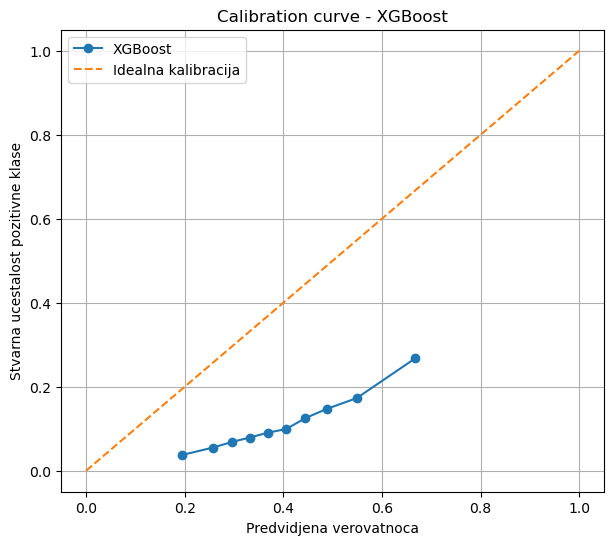

In [51]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_train,
    oof_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Idealna kalibracija"
)

plt.xlabel("Predvidjena verovatnoca")
plt.ylabel("Stvarna ucestalost pozitivne klase")
plt.title("Calibration curve - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

In [52]:
cal_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

cal_train_idx, cal_valid_idx = next(
    cal_split.split(
        oof_proba,
        y_train,
        groups=train_patient_ids
    )
)

oof_proba_cal_train = oof_proba[cal_train_idx]
oof_proba_cal_valid = oof_proba[cal_valid_idx]

y_cal_train = y_train.iloc[cal_train_idx]
y_cal_valid = y_train.iloc[cal_valid_idx]

In [53]:
from sklearn.linear_model import LogisticRegression

calibrator_sigmoid = LogisticRegression()

calibrator_sigmoid.fit(
    oof_proba_cal_train.reshape(-1, 1),
    y_cal_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [54]:
calibrated_proba_valid = calibrator_sigmoid.predict_proba(
    oof_proba_cal_valid.reshape(-1, 1)
)[:, 1]

In [55]:
from sklearn.metrics import brier_score_loss

brier_before = brier_score_loss(
    y_cal_valid,
    oof_proba_cal_valid
)

brier_after = brier_score_loss(
    y_cal_valid,
    calibrated_proba_valid
)

print("Brier pre kalibracije:", brier_before)
print("Brier nakon kalibracije:", brier_after)

Brier pre kalibracije: 0.18438758637835534
Brier nakon kalibracije: 0.09831572038243516


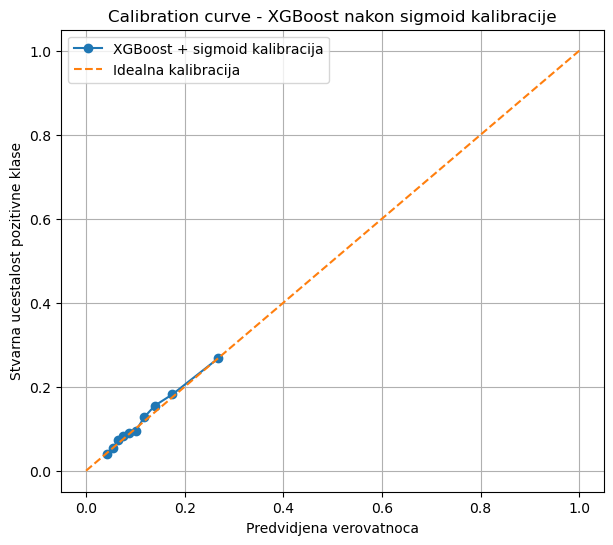

In [56]:
prob_true_sigmoid, prob_pred_sigmoid = calibration_curve(
    y_cal_valid,
    calibrated_proba_valid,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred_sigmoid,
    prob_true_sigmoid,
    marker="o",
    label="XGBoost + sigmoid kalibracija"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Idealna kalibracija"
)

plt.xlabel("Predvidjena verovatnoca")
plt.ylabel("Stvarna ucestalost pozitivne klase")
plt.title("Calibration curve - XGBoost nakon sigmoid kalibracije")
plt.legend()
plt.grid(True)
plt.show()

In [57]:
threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):

    y_pred = (
        calibrated_proba_valid >= threshold
    ).astype(int)

    precision = precision_score(
        y_cal_valid,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_cal_valid,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_cal_valid,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)


,threshold,precision,recall,f1
8,0.13,0.203964,0.503340,0.290295
9,0.14,0.213848,0.451196,0.290168
10,0.15,0.223279,0.404654,0.287772
7,0.12,0.192879,0.556777,0.286506
6,0.11,0.183365,0.619910,0.283016
11,0.16,0.228852,0.356173,0.278658
12,0.17,0.241081,0.324715,0.276717
5,0.10,0.172096,0.675070,0.274271
13,0.18,0.247946,0.292609,0.268432
4,0.09,0.162329,0.731092,0.265670


In [58]:
best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax(), "threshold"
]

chosen_threshold_calibrated = best_threshold

y_test_proba = best_xgb.predict_proba(test)[:, 1]

y_test_proba_sigmoid = calibrator_sigmoid.predict_proba(
    y_test_proba.reshape(-1, 1)
)[:, 1]

y_test_pred_calibrated = (
    y_test_proba_sigmoid >= chosen_threshold_calibrated
).astype(int)

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_test_pred_calibrated)
precision = precision_score(y_test, y_test_pred_calibrated, zero_division=0)
recall = recall_score(y_test, y_test_pred_calibrated, zero_division=0)
f1 = f1_score(y_test, y_test_pred_calibrated, zero_division=0)
auc = roc_auc_score(y_test, y_test_proba_sigmoid)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("AUC:", auc)

Accuracy: 0.7106352893647107
Precision: 0.1905600563578725
Recall: 0.48826714801444043
F1: 0.27413225234355204
AUC: 0.6718891966082309


In [60]:
import joblib
final_model = {
    "xgboost": best_xgb,
    "calibrator": calibrator_sigmoid,
    "threshold": 0.13
}

joblib.dump(
    final_model,
    "final_model.pkl"
)

['final_model.pkl']

In [61]:
!pip install shap
import shap
import matplotlib.pyplot as plt

In [62]:
print(shap.__version__)

0.52.0


In [63]:
preprocessor = best_xgb.named_steps["preprocessor"]
xgb_model = best_xgb.named_steps["model"]

X_test_transformed = preprocessor.transform(test)

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

print("Broj feature-a:", len(feature_names))
print("Dimenzije:", X_test_transformed.shape)

Broj feature-a: 296
Dimenzije: (19802, 296)


In [64]:
X_shap = X_test_transformed[:2000]

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_shap)

print("Dimenzije SHAP vrednosti:", shap_values.shape)

Dimenzije SHAP vrednosti: (2000, 296)


C:\Users\PC\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


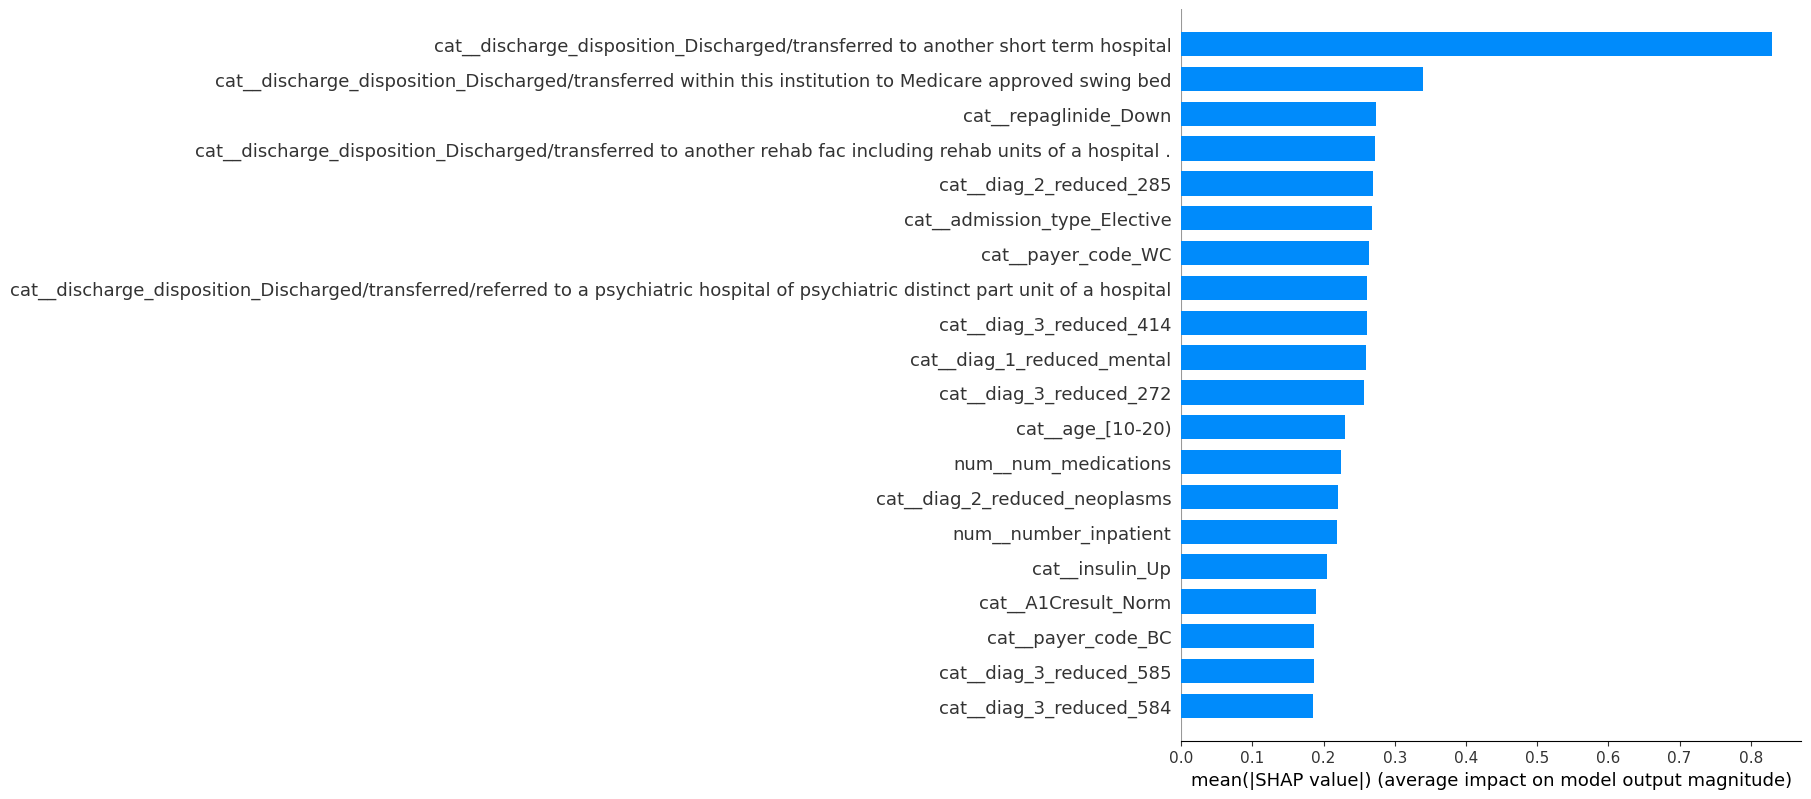

In [65]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar"
)

C:\Users\PC\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


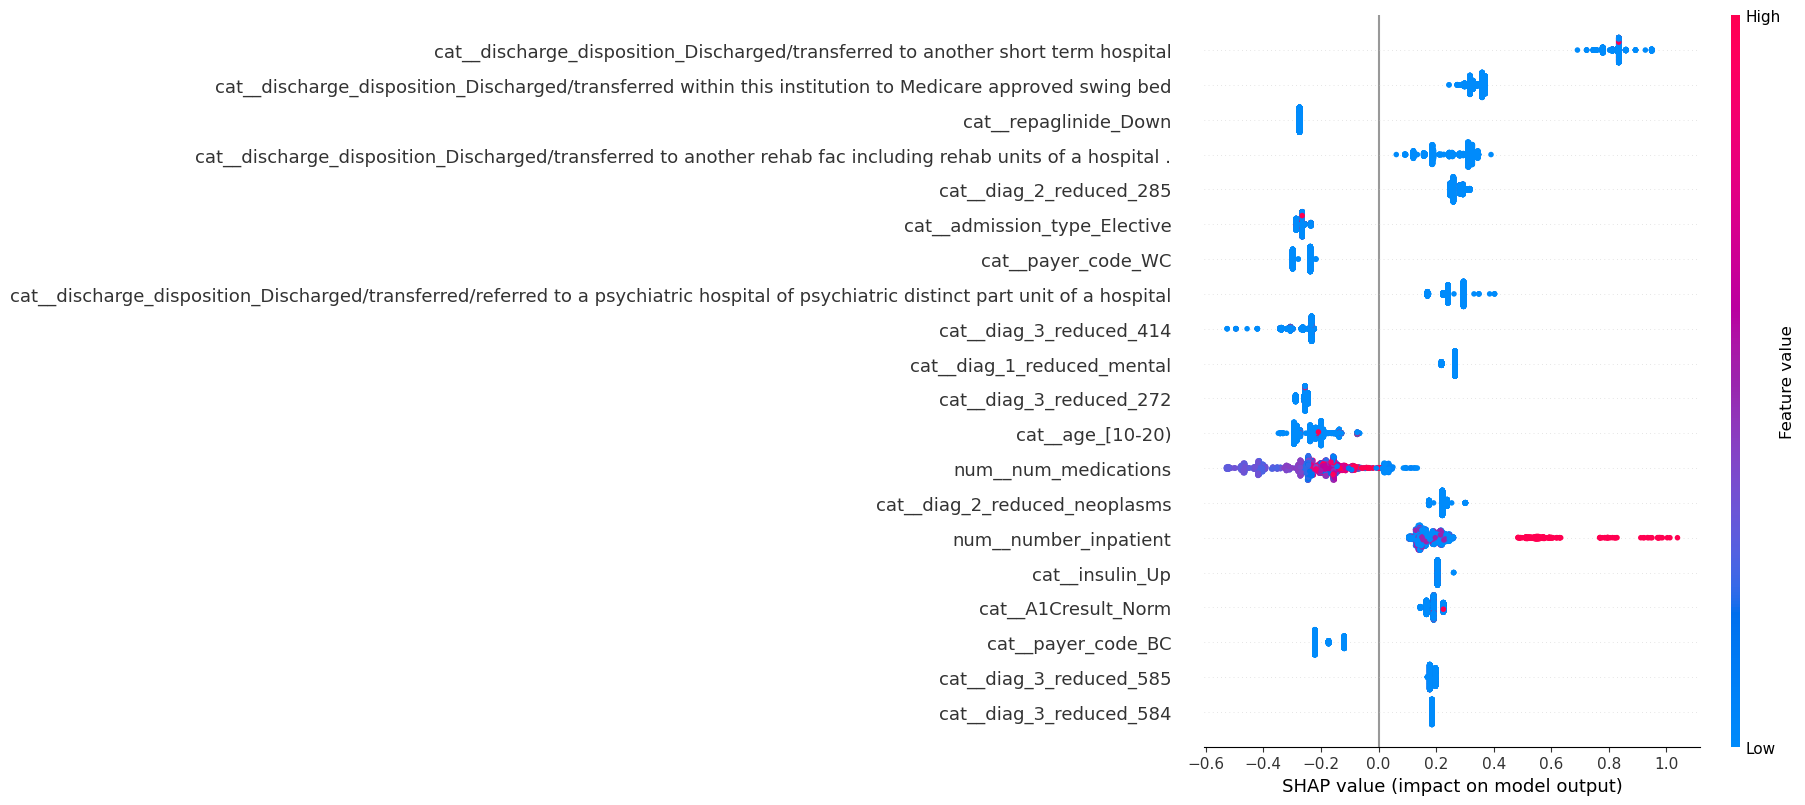

In [66]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names
)

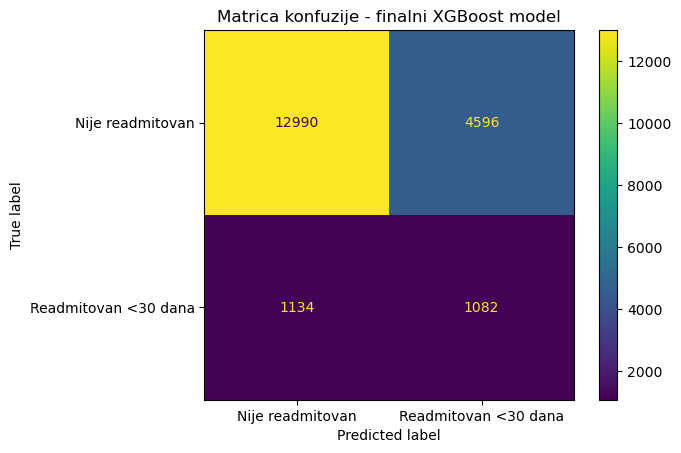

In [67]:
cm = confusion_matrix(y_test, y_test_pred_calibrated)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Nije readmitovan", "Readmitovan <30 dana"]
)

disp.plot()
plt.title("Matrica konfuzije - finalni XGBoost model")
plt.show()

In [68]:
print(
    classification_report(
        y_test,
        y_test_pred_calibrated,
        target_names=["Nije readmitovan", "Readmitovan <30 dana"]
    )
)

                      precision    recall  f1-score   support

    Nije readmitovan       0.92      0.74      0.82     17586
Readmitovan <30 dana       0.19      0.49      0.27      2216

            accuracy                           0.71     19802
           macro avg       0.56      0.61      0.55     19802
        weighted avg       0.84      0.71      0.76     19802



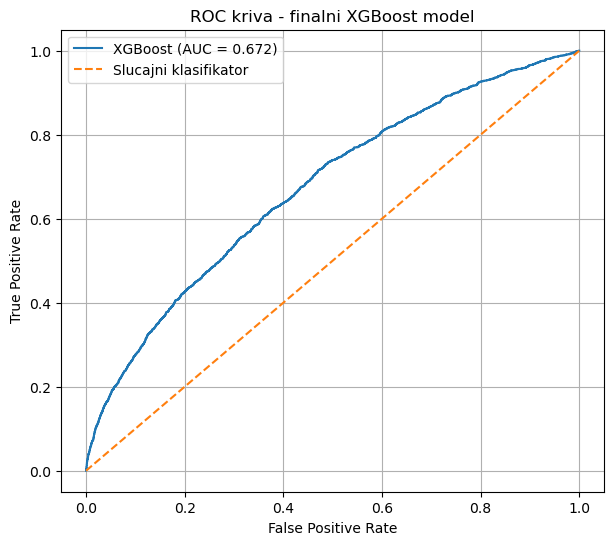

AUC: 0.6718891966082309


In [69]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(
    y_test,
    y_test_proba_sigmoid
)

auc_score = roc_auc_score(
    y_test,
    y_test_proba_sigmoid
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Slucajni klasifikator"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC kriva - finalni XGBoost model")
plt.legend()
plt.grid(True)
plt.show()

print("AUC:", auc_score)

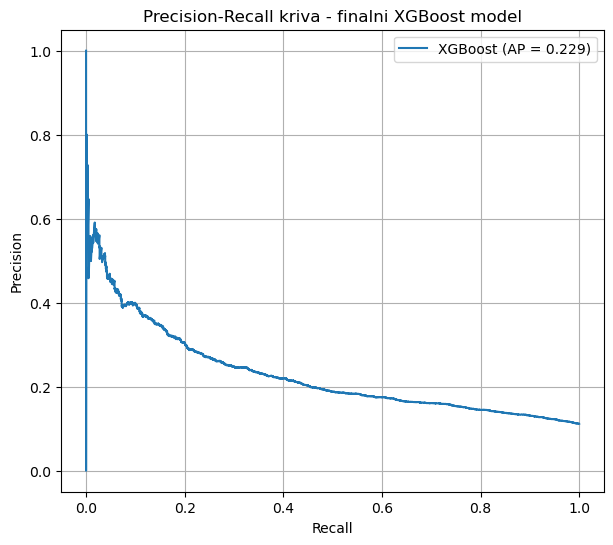

Average Precision: 0.22882943550706947


In [70]:
from sklearn.metrics import precision_recall_curve, average_precision_score
precision, recall, _ = precision_recall_curve(
    y_test,
    y_test_proba_sigmoid
)

ap = average_precision_score(
    y_test,
    y_test_proba_sigmoid
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label=f"XGBoost (AP = {ap:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall kriva - finalni XGBoost model")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision:", ap)

In [71]:
print(best_models["XGBoost"].named_steps.keys())

dict_keys(['rare_grouper', 'custom_imputer', 'feature_selector', 'preprocessor', 'model'])


In [72]:
selector = best_models["XGBoost"].named_steps["feature_selector"]

print(selector.__dict__.keys())

dict_keys(['numeric_columns', 'categorical_columns', 'selection_percentile', 'categorical_prevalence_threshold', 'numeric_correlation_threshold', 'categorical_correlation_threshold'])
